# 01 — Exploração da base Olist

## Objetivo
Conhecer a estrutura e a qualidade inicial da tabela de avaliações antes de preparar a base de conhecimento do RAG.

Este notebook usa a implementação de leitura de `src/data/loader.py`. Os CSVs originais não são versionados no Git: baixe o Brazilian E-Commerce Public Dataset by Olist e coloque os arquivos em `data/raw/`.

**Entrada principal:** `olist_order_reviews_dataset.csv`.

**Saída esperada:** compreensão das dimensões, campos, valores ausentes, distribuição das notas e disponibilidade de comentários.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW_DIR = ROOT / "data" / "raw"
from src.data.loader import load_reviews

REVIEWS_FILE = RAW_DIR / "olist_order_reviews_dataset.csv"
reviews = load_reviews(REVIEWS_FILE)

print(f"Linhas: {len(reviews):,}")
print(f"Colunas: {len(reviews.columns)}")
display(reviews.head())


Linhas: 99,224
Colunas: 7


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


## 1. Estrutura dos dados

Verifique tipos, campos e dimensões para entender o que está disponível na fonte.

In [2]:
reviews.info()
display(reviews.describe(include="all").T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
review_id,99224,98410,08528f70f579f0c830189efc523d2182,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,99224,98673,df56136b8031ecd28e200bb18e6ddb2e,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_score,99224.0,NaN,NaN,NaN,4.086421,1.347579,1.0,4.0,5.0,5.0,5.0
review_comment_title,11568,4527,Recomendo,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_comment_message,40977,36159,Muito bom,230,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_creation_date,99224,636,2017-12-19 00:00:00,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_answer_timestamp,99224,98248,2017-06-15 23:21:05,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Valores ausentes

A ausência de comentário é relevante para o RAG: registros sem texto não podem compor documentos semânticos, mas continuam fazendo parte da tabela original.

In [3]:
missing = reviews.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(reviews) * 100).round(2)
quality = __import__("pandas").DataFrame({"ausentes": missing, "ausentes_%": missing_pct})
display(quality)


,ausentes,ausentes_%
review_comment_title,87656,88.34
review_comment_message,58247,58.70
review_id,0,0.00
review_score,0,0.00
order_id,0,0.00
review_creation_date,0,0.00
review_answer_timestamp,0,0.00


## 3. Distribuição das notas

A nota é um metadado útil para segmentar a voz do cliente, embora não substitua a leitura do comentário.

,quantidade
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


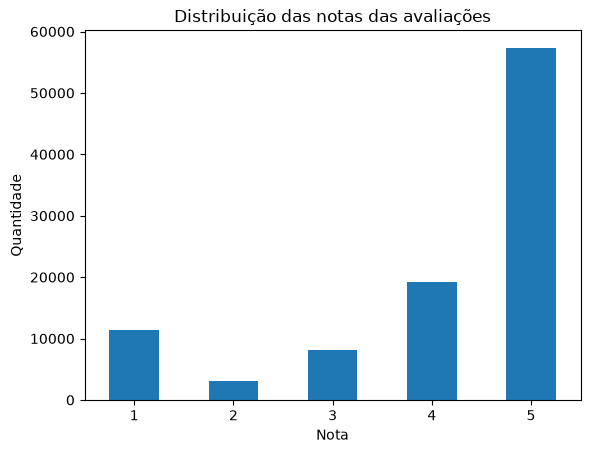

In [4]:
import matplotlib.pyplot as plt

score_counts = reviews["review_score"].value_counts().sort_index()
display(score_counts.rename("quantidade").to_frame())
ax = score_counts.plot(kind="bar", rot=0, title="Distribuição das notas das avaliações")
ax.set_xlabel("Nota")
ax.set_ylabel("Quantidade")
plt.show()


## 4. Comentários e datas

Compare o volume de comentários preenchidos e observe a extensão dos textos.

In [5]:
import pandas as pd

comments = reviews["review_comment_message"].fillna("").astype(str).str.strip()
non_empty = comments.ne("")
lengths = comments[non_empty].str.len()

print(f"Avaliações com comentário: {non_empty.sum():,} ({non_empty.mean():.1%})")
print(f"Avaliações sem comentário: {(~non_empty).sum():,}")
display(lengths.describe().to_frame("caracteres"))
display(reviews["review_creation_date"].head())


Avaliações com comentário: 40,950 (41.3%)
Avaliações sem comentário: 58,274


,caracteres
count,40950.000000
mean,68.398364
std,53.833227
min,1.000000
25%,28.000000
50%,53.000000
75%,94.000000
max,208.000000


0    2018-01-18 00:00:00
1    2018-03-10 00:00:00
2    2018-02-17 00:00:00
3    2017-04-21 00:00:00
4    2018-03-01 00:00:00
Name: review_creation_date, dtype: object

## 5. Amostra de avaliações

Inspecione exemplos reais para verificar o idioma, o estilo e o tipo de informação presente nos comentários.

In [6]:
sample = reviews.loc[non_empty, ["review_id", "review_score", "review_creation_date", "review_comment_message"]].sample(
    n=min(10, int(non_empty.sum())), random_state=42
)
display(sample)


,review_id,review_score,review_creation_date,review_comment_message
18036,232c96ccef267c81d18f3767192d9f8a,5,2018-03-06 00:00:00,SEM QUEIXAS
89184,4d44ff032368cbb3ab167eac6aaed19b,4,2017-10-17 00:00:00,Produto chegou conforme descrito e antes do pr...
74375,b1a6c69017a11a1c74dbf7366ec53ba8,3,2018-08-18 00:00:00,demora na entrega. e produto pesado demais
31028,588b6e91b1c2aaff5c1aa72bafd2a163,5,2017-10-10 00:00:00,Fui muiro bem atendido.
33213,2e4b8331c7be99dadd0c2db785bb1134,5,2018-03-03 00:00:00,Muito bom
13053,e50dcf17328c591faa7aa524cf4e4a3e,5,2018-08-24 00:00:00,produto entregue no prazo e muito bem embalado...
46896,ba03c9570d785f8b49f6a37d4a63ea99,5,2018-02-21 00:00:00,A LOJA É MUITO CONFIÁVEL E ATENCIOSA.
62557,a557f612bad9e7ddada4cbe88154ed3c,5,2018-08-30 00:00:00,"Excelente, recebi um dia antes do prazo e muit..."
87537,ed0c0e2857e70873fad29ed1ff5253d4,2,2017-11-29 00:00:00,"oi e como fica o produto,que ate agora não che..."
86992,9e99bd7dc75c451c41d5e9a360bb3d75,5,2018-01-11 00:00:00,Recomendo


## 6. Conclusões da exploração

Registre aqui, após executar o notebook, observações sobre:

- proporção de avaliações com texto;
- distribuição das notas;
- campos com maior ausência;
- limitações identificadas na fonte;
- decisões que serão tratadas no notebook de preparação.

**Próxima etapa:** [02 — Preparação da base](02_preparacao_base.ipynb).